<a href="https://colab.research.google.com/github/MashrufAhmed-470/machine-learning/blob/main/FINAL_VIZ_PROJECT_Handwriting_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Handwritten Text Detection using EasyOCR and PyTorch**
Done by Mashruf Ahmed Zafri
T00657643

The training and the technique for this project was based on Nicholas Renotte's Optical Character Recognition with EasyOCR and Python | OCR PyTorch project.

This is the link to his github repository:
https://github.com/nicknochnack/EasyOCR/blob/main/OCR%20Basics-EasyOCR.ipynb

In [ ]:
!pip install torch torchvision torchaudio
!pip install easyocr
import easyocr
import cv2
from matplotlib import pyplot as plt
import numpy as np

In [ ]:
# NOT NEEDED
#!apt-get install tesseract-ocr
#!apt-get install libtesseract-dev
#!pip install pytesseract
#import pytesseract
#from PIL import Image

# Set the path to the Tesseract executable
#pytesseract.pytesseract.tesseract_cmd = r'/usr/bin/tesseract'

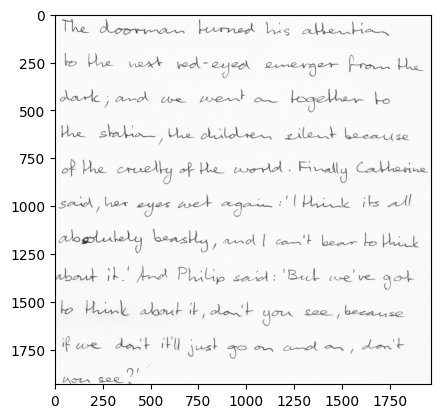

In [ ]:
#from google.colab import files
#uploaded = files.upload()
#image_path = list(uploaded.keys())[0]  # Get the uploaded image path
#original_image = cv2.imread(image_path)  # Read the image

IMAGE_PATH = 'doorman.png' # NOTE FOR PROFESSOR: I have included all the images I have used for the test cases in a zip file. Please feel free to change the file name here to check the outputs.
# Read the image
original_image = cv2.imread(IMAGE_PATH)
plt.imshow(original_image)

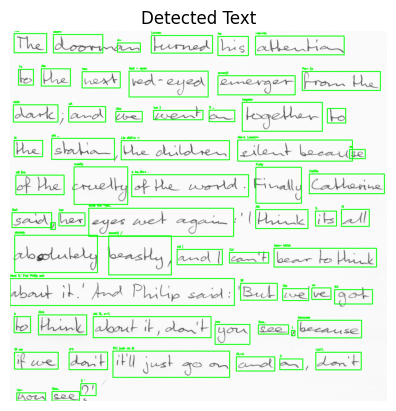



Detected Sentence:
 The doorv A~ Lurnex hs ~le~Ha 1o Ale hex bed - eyea evnevjt Po~ (e datk aA Ubz 0 _ kegeler  Ie shl _ Lle dldl1e ~ Ale~L LoecU= se o8 |he s ke_Wo+ . Calltie SaA 1 her eJes wct ~jai_ Aik iL Al ad | bea~ bAizk Abot il,' Fnd Philip sai: Bi l3e ve b Aink akl %, x~'L Soe_ 1 because you iR we d'4 iFU jush Jo & 0L~A 2 Lon'L 2 ' Uo^ See_ lue } FxAly cueAly baasHj / abolely Ca' 94


In [ ]:
###########    Preprocessing by Mashruf    ############
# FINAL VERSION
# Gave the best results

# Converting the image to grayscale
gray_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2GRAY)

# Image smoothing for noise reduction using Gaussian Blur
#smoothed_image = cv2.medianBlur(gray_image, 5)
smoothed_image = cv2.GaussianBlur(gray_image, (5, 5), 0)
#smoothed_image = cv2.bilateralFilter(gray_image, 9, 75, 75)
#smoothed_image = cv2.fastNlMeansDenoising(gray_image, None, h=10, templateWindowSize=7, searchWindowSize=21)

# Enhance text visibility (need to increase this for further test cases)
_, binary_image = cv2.threshold(smoothed_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
blurred_image = cv2.GaussianBlur(binary_image, (5, 5), 0)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced_image = clahe.apply(blurred_image)

# Morphological Operations
kernel = np.ones((3, 3), np.uint8)
eroded_image = cv2.erode(enhanced_image, kernel, iterations=1)
dilated_image = cv2.dilate(eroded_image, kernel, iterations=1)

# EasyOCR for text recognition
reader = easyocr.Reader(['en'])
result = reader.readtext(dilated_image)

# Extracting detected words
detected_words = [detection[1] for detection in result]

# Displaying the original image with bounding boxes around words
for detection in result:
    top_left = tuple(map(int, detection[0][0]))
    bottom_right = tuple(map(int, detection[0][2]))
    text = detection[1]

    cv2.rectangle(original_image, top_left, bottom_right, (0, 255, 0), 3)
    cv2.putText(original_image, text, (top_left[0], top_left[1] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2,
                cv2.LINE_AA)

#plt.imshow
plt.imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
plt.title('Detected Text')
plt.axis('off')
plt.show()

# Printing sentence
sentence = ' '.join(detected_words)
print("")
print("")
print("Detected Sentence:\n", sentence)

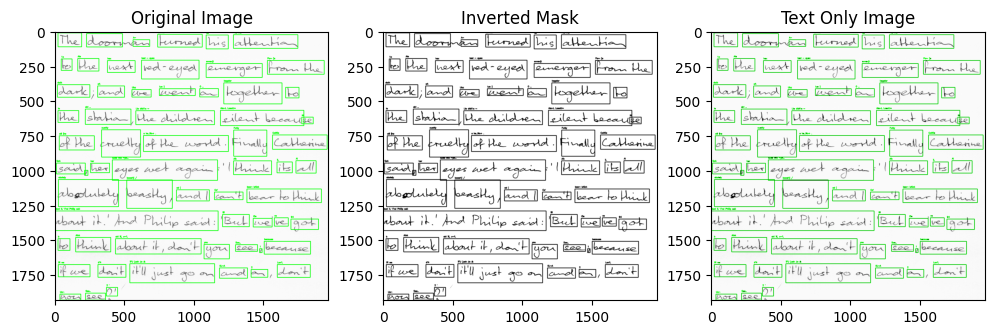

In [ ]:
###########    Preprocessing by Mashruf    ############
#VERSION 2
# Applying all the image preprocessings I can think of.
# Fine tuned a little from VERSION 1

# grayscale
gray_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2GRAY)

# thresholding
_, binary_mask = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Noise Reduction by Gaussian Blur
blurred_mask = cv2.GaussianBlur(binary_mask, (5, 5), 0)

# Invert the mask to highlight text
inverted_mask = cv2.bitwise_not(blurred_mask)

# Apply the inverted mask to the original image (Need to remove this, does not help)
text_only_image = cv2.bitwise_and(original_image, original_image, mask=inverted_mask)

# Display the results
plt.figure(figsize=(12, 6))

plt.subplot(131)
plt.imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')

plt.subplot(132)
plt.imshow(inverted_mask, cmap='gray')
plt.title('Inverted Mask')

# Still outputs the original image with bounding boxes
plt.subplot(133)
plt.imshow(cv2.cvtColor(text_only_image, cv2.COLOR_BGR2RGB))
plt.title('Text Only Image')

plt.show()

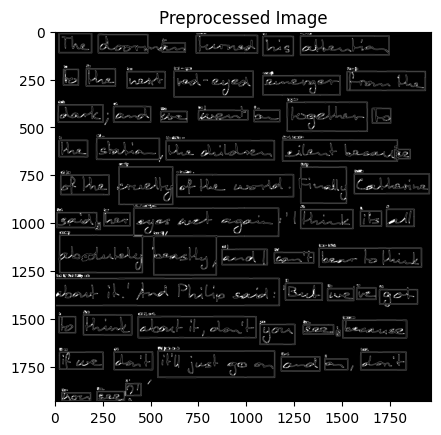

In [ ]:
###########    Preprocessing by Mashruf    ############
#VERSION 1

# Grayscale
gray_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2GRAY)

# Thresholding
_, binary_image = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Gaussian Blur
blurred_image = cv2.GaussianBlur(binary_image, (5, 5), 0)

# Contrast Enhancement (CLAHE)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced_image = clahe.apply(blurred_image)

# Edge Detection (Canny)
edges_image = cv2.Canny(enhanced_image, 100, 200)

# Dilation and Erosion
kernel = np.ones((3, 3), np.uint8)
dilated_image = cv2.dilate(edges_image, kernel, iterations=1)
eroded_image = cv2.erode(dilated_image, kernel, iterations=1)

# Text Localization (Contour Detection)
contours, _ = cv2.findContours(eroded_image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Display the preprocessed image
plt.imshow(eroded_image, cmap='gray')
plt.title('Preprocessed Image')
plt.show()

Text(0.5, 1.0, 'Original Image 3')

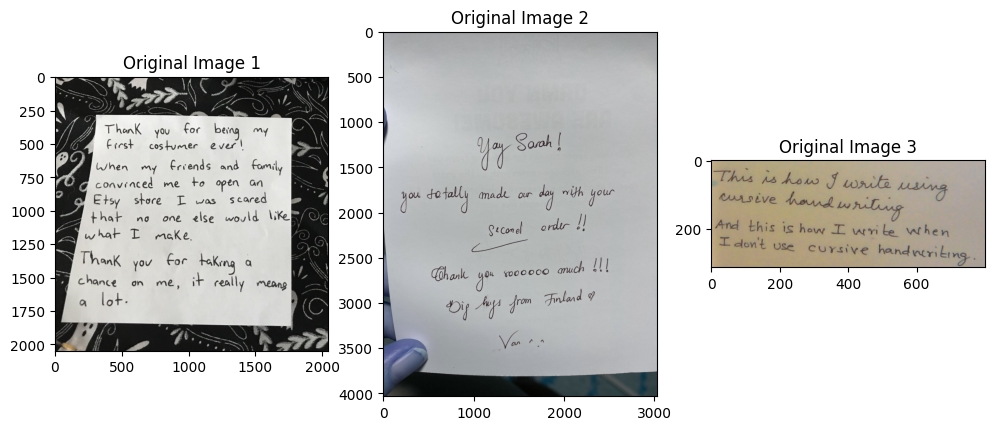

In [ ]:
# TRYING MULTIPLE IMAGES AT ONCE

IMAGE_PATH_1 = 'thank.jpg'
IMAGE_PATH_2 = 'sarah.jpg'
IMAGE_PATH_3 = 'ez.jpg'

# Read the image

original_image1 = cv2.imread(IMAGE_PATH_1)
original_image2 = cv2.imread(IMAGE_PATH_2)
original_image3 = cv2.imread(IMAGE_PATH_3)

# Display the results
plt.figure(figsize=(12, 6))

plt.subplot(131)
plt.imshow(cv2.cvtColor(original_image1, cv2.COLOR_BGR2RGB))
plt.title('Original Image 1')

plt.subplot(132)
plt.imshow(original_image2, cmap='gray')
plt.title('Original Image 2')

plt.subplot(133)
plt.imshow(original_image3, cmap='gray')
plt.title('Original Image 3')

# Extract text using Tesseract OCR

# DOES NOT WORK PROPERLY
detected_words = []

for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    roi = original_image[y:y + h, x:x + w]

    # Convert the ROI to grayscale
    roi_gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

    # Save the ROI as a temporary image file
    temp_image_path = 'temp_roi.png'
    cv2.imwrite(temp_image_path, roi_gray)

    # Perform OCR using Tesseract
    text = pytesseract.image_to_string(Image.open(temp_image_path), config='--psm 6')

    # Filter out non-alphanumeric characters
    clean_text = ''.join(c for c in text if c.isalnum() or c.isspace())

    detected_words.append(clean_text)

# Print all the detected words in a single sentence without line breaks
sentence = ' '.join(detected_words)
print("Detected Sentence:", sentence)

# Display the original image
plt.imshow(cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.show()

In [ ]:
# Initialize EasyOCR reader
#reader = easyocr.Reader(['en'])
#img_with_text = original_image.copy()  # Fix: Initialize img_with_text

In [ ]:
#SINGLE WORD

#img = final_image
#img = cv2.rectangle(img,top_left,bottom_right,(0,255,0),3)
#img = cv2.putText(img,text,top_left, font, 0.5,(255,255,255),2,cv2.LINE_AA)
#plt.imshow(img)
#plt.show()